#### Data Mining Project by Cecilia Muniz Siqueira

#### Initial setup, import necessary libraries, and dataset loading

In [30]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from mlxtend.frequent_patterns import apriori, association_rules
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import accuracy_score

# Set visual styling for publication-ready charts
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 11, "figure.autolayout": True})

# Load Dataset
df = pd.read_csv("ai_student_impact_dataset.csv")

print("Dataset Overview")
print(f"Total Rows: {df.shape[0]}, Total Columns: {df.shape[1]}")
print("\nMissing Values per Column:")
print(df.isnull().sum())
print("\nBasic Summary Statistics:")
display(df.describe(include=["number"]))

Dataset Overview
Total Rows: 50000, Total Columns: 16

Missing Values per Column:
Student_ID                    0
Major_Category                0
Year_of_Study                 0
Pre_Semester_GPA              0
Weekly_GenAI_Hours            0
Primary_Use_Case              0
Prompt_Engineering_Skill      0
Tool_Diversity                0
Paid_Subscription             0
Traditional_Study_Hours       0
Perceived_AI_Dependency       0
Institutional_Policy          0
Anxiety_Level_During_Exams    0
Post_Semester_GPA             0
Skill_Retention_Score         0
Burnout_Risk_Level            0
dtype: int64

Basic Summary Statistics:


,Student_ID,Pre_Semester_GPA,Weekly_GenAI_Hours,Tool_Diversity,Traditional_Study_Hours,Perceived_AI_Dependency,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score
count,50000.000000,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,125000.500000,3.146102,8.427752,2.80026,11.209271,3.505360,4.270760,3.349299,75.798125
std,14433.901067,0.478854,8.269490,1.18802,5.156426,1.820812,2.144066,0.495673,13.281626
min,100001.000000,1.183000,0.000000,1.00000,1.000000,1.000000,1.000000,1.000000,10.780000
25%,112500.750000,2.834000,2.390000,2.00000,7.560000,2.000000,3.000000,3.023750,66.820000
50%,125000.500000,3.210000,5.800000,3.00000,11.180000,3.000000,4.000000,3.421000,76.000000
75%,137500.250000,3.521000,11.720000,4.00000,14.710000,5.000000,6.000000,3.749000,85.190000
max,150000.000000,3.998000,40.000000,5.00000,35.860000,10.000000,10.000000,4.000000,100.000000


#### EDA with Correlation Matrix & Major Disparities

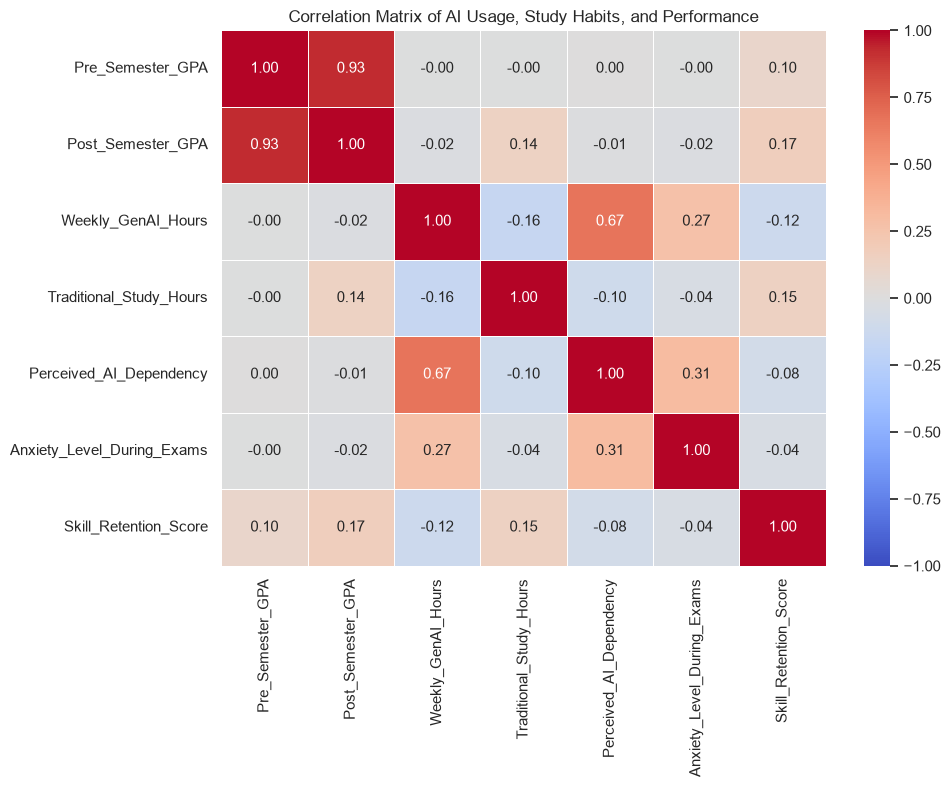

C:\Users\cecil\AppData\Local\Temp\ipykernel_23556\132527428.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\cecil\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
C:\Users\cecil\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
C:\Users\cecil\AppD

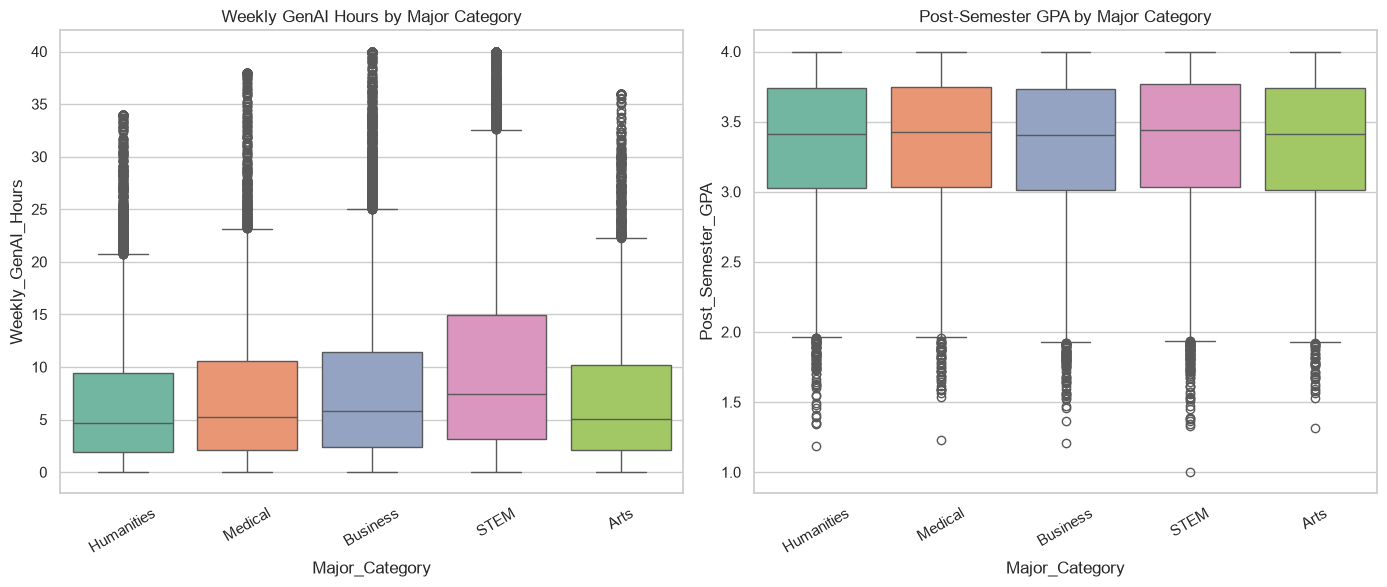

In [31]:
# Correlation Matrix & Heatmap (Numerical Features)
plt.figure(figsize=(10, 8))
num_cols = [
    "Pre_Semester_GPA",
    "Post_Semester_GPA",
    "Weekly_GenAI_Hours",
    "Traditional_Study_Hours",
    "Perceived_AI_Dependency",
    "Anxiety_Level_During_Exams",
    "Skill_Retention_Score",
]

corr_matrix = df[num_cols].corr()
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
)
plt.title("Correlation Matrix of AI Usage, Study Habits, and Performance")
plt.savefig("correlation_heatmap.png", dpi=300)
plt.show()

# Major Disparities Analysis (Categorical vs. Continuous)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.boxplot(
    data=df,
    x="Major_Category",
    y="Weekly_GenAI_Hours",
    palette="Set2",
    ax=axes[0],
)
axes[0].set_title("Weekly GenAI Hours by Major Category")
axes[0].tick_params(axis="x", rotation=30)

sns.boxplot(
    data=df,
    x="Major_Category",
    y="Post_Semester_GPA",
    palette="Set2",
    ax=axes[1],
)
axes[1].set_title("Post-Semester GPA by Major Category")
axes[1].tick_params(axis="x", rotation=30)

plt.savefig("major_disparities.png", dpi=300)
plt.show()

## Some Theoretical & Mathematical Framework

To rigorously analyze student behavioral patterns, this project leverages foundational data mining and machine learning principles:

* **Distance & Similarity Metrics:** Unsupervised techniques such as **K-Means Clustering** rely on distance metrics (e.g., Euclidean distance) in the standardized feature space to partition students into distinct behavioral archetypes. Similarly, **Principal Component Analysis (PCA)** maximizes variance through eigenvalue decomposition of the feature covariance matrix.
* **Information Theory & Entropy:** Supervised classification models (such as **Random Forest**) construct decision boundaries by evaluating Information Gain, which is rooted in **Shannon Entropy** ($H(X) = -sum P(x) \log P(x)$) to measure purity across classification splits.
* **Probabilistic Divergence:** To evaluate distributional shifts between student groups (e.g., comparing feature distributions across anxiety tiers), divergence measures quantify how one probability distribution differs from a reference distribution.

In [41]:
print("Correlation Analysis & Conclusions")
print("=" * 50)

# Extract unique variable pairs (excluding self-correlations and symmetric duplicates)
pairs = []
seen_pairs = set()

for (col_a, col_b), val in corr_matrix.unstack().items():
    if col_a == col_b:
        continue
    pair_key = tuple(sorted((col_a, col_b)))
    if pair_key not in seen_pairs:
        seen_pairs.add(pair_key)
        pairs.append((col_a, col_b, val))

corr_pairs_df = (
    pd.DataFrame(pairs, columns=["Feature_1", "Feature_2", "r"])
    .sort_values("r", ascending=False)
    .reset_index(drop=True)
)

# Top Positive Linear Correlations
print("\nTop Positive Relationships:")
for _, row in corr_pairs_df.head(3).iterrows():
    print(f"  • {row['Feature_1']} -- {row['Feature_2']}: r = {row['r']:.2f}")

# Top Negative (Inverse) Linear Correlations
print("\nTop Inverse/Negative Relationships:")
for _, row in corr_pairs_df.tail(3).sort_values("r", ascending=True).iterrows():
    print(f"  • {row['Feature_1']} -- {row['Feature_2']}: r = {row['r']:.2f}")

Correlation Analysis & Conclusions

Top Positive Relationships:
  • Pre_Semester_GPA -- Post_Semester_GPA: r = 0.93
  • Weekly_GenAI_Hours -- Perceived_AI_Dependency: r = 0.67
  • Perceived_AI_Dependency -- Anxiety_Level_During_Exams: r = 0.31

Top Inverse/Negative Relationships:
  • Weekly_GenAI_Hours -- Traditional_Study_Hours: r = -0.16
  • Weekly_GenAI_Hours -- Skill_Retention_Score: r = -0.12
  • Traditional_Study_Hours -- Perceived_AI_Dependency: r = -0.10


#### Non-Linear Threshold Analysis and Cognition Retention Trade-offs

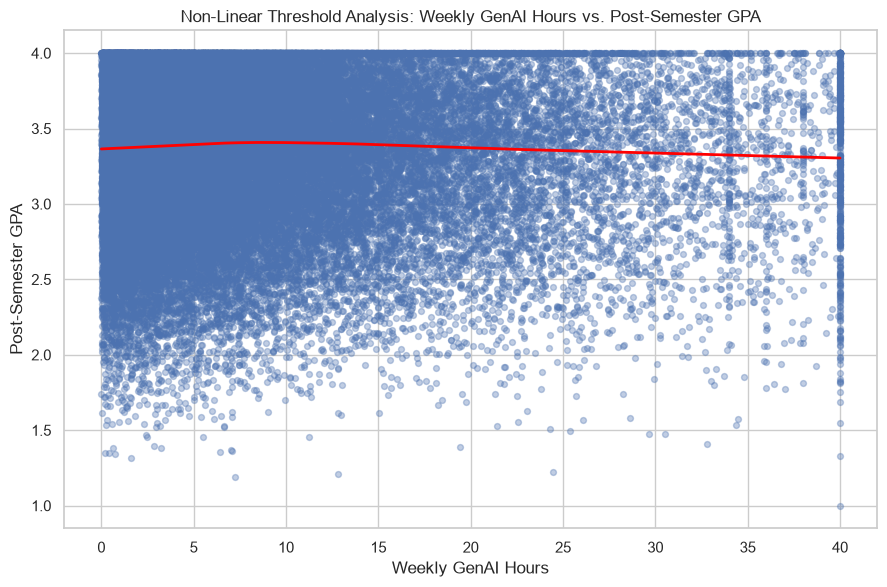

C:\Users\cecil\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
C:\Users\cecil\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
C:\Users\cecil\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientati

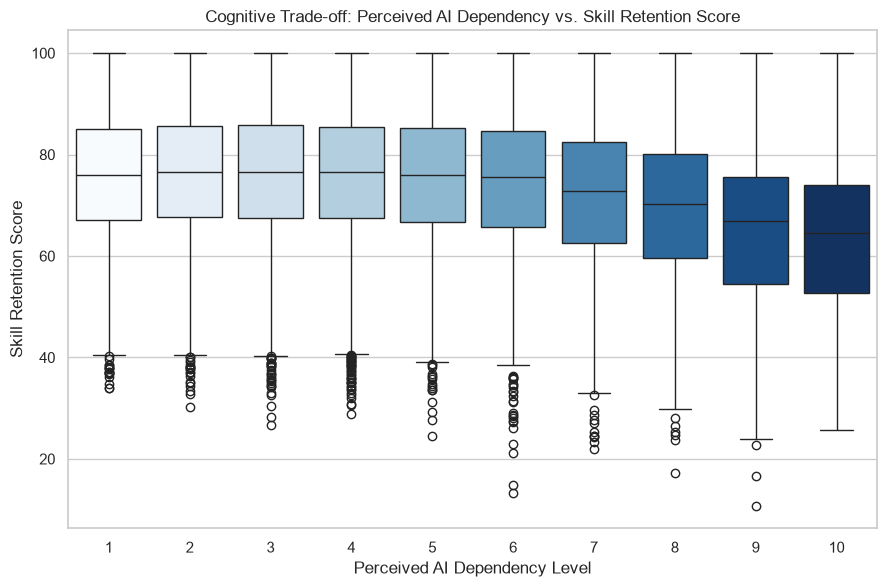

Visual EDA complete; plots saved to disk.


In [42]:
# Non-Linear Threshold Analysis (LOESS Curve)
plt.figure(figsize=(9, 6))
sns.regplot(
    data=df,
    x="Weekly_GenAI_Hours",
    y="Post_Semester_GPA",
    scatter_kws={"alpha": 0.35, "s": 18},
    line_kws={"color": "red", "linewidth": 2},
    lowess=True,
)
plt.title(
    "Non-Linear Threshold Analysis: Weekly GenAI Hours vs. Post-Semester GPA"
)
plt.xlabel("Weekly GenAI Hours")
plt.ylabel("Post-Semester GPA")
plt.tight_layout()
plt.savefig("threshold_analysis_gpa.png", dpi=300)
plt.show()

# Retention Trade-off: Dependency vs. Skill Retention
plt.figure(figsize=(9, 6))
sns.boxplot(
    data=df,
    x="Perceived_AI_Dependency",
    y="Skill_Retention_Score",
    hue="Perceived_AI_Dependency",
    palette="Blues",
    legend=False,
)
plt.title(
    "Cognitive Trade-off: Perceived AI Dependency vs. Skill Retention Score"
)
plt.xlabel("Perceived AI Dependency Level")
plt.ylabel("Skill Retention Score")
plt.tight_layout()
plt.savefig("retention_tradeoff.png", dpi=300)
plt.show()

print("Visual EDA complete; plots saved to disk.")

#### Preprocessing, Scaling, and PCA

In [43]:
df_fe = df.copy()
df_fe["GPA_Delta"] = df_fe["Post_Semester_GPA"] - df_fe["Pre_Semester_GPA"]

# Select numerical & ordinal features for our machine learning pipeline
features = [
    "Weekly_GenAI_Hours",
    "Traditional_Study_Hours",
    "Perceived_AI_Dependency",
    "Anxiety_Level_During_Exams",
    "Skill_Retention_Score",
    "GPA_Delta",
]

X = df_fe[features].dropna()

# Standardize features to mean=0, variance=1
# (Critical for both PCA and distance-based clustering like K-Means)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply PCA right after scaling
pca = PCA(n_components=6)
X_pca = pca.fit_transform(X_scaled)

print(f"Explained Variance by PC1: {pca.explained_variance_ratio_[0]*100:.1f}%")
print(f"Explained Variance by PC2: {pca.explained_variance_ratio_[1]*100:.1f}%")
print(f"Explained Variance by PC3: {pca.explained_variance_ratio_[2]*100:.1f}%")
print(f"Explained Variance by PC4: {pca.explained_variance_ratio_[3]*100:.1f}%")
print(f"Explained Variance by PC5: {pca.explained_variance_ratio_[4]*100:.1f}%")
print(f"Explained Variance by PC6: {pca.explained_variance_ratio_[5]*100:.1f}%")    
print(f"Total Variance Captured by 6 Components: {pca.explained_variance_ratio_.sum()*100:.1f}%")

Explained Variance by PC1: 32.9%
Explained Variance by PC2: 23.2%
Explained Variance by PC3: 14.7%
Explained Variance by PC4: 13.6%
Explained Variance by PC5: 10.1%
Explained Variance by PC6: 5.5%
Total Variance Captured by 6 Components: 100.0%


In [45]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=[f"PC{i+1}" for i in range(pca.n_components_)],
)
display(loadings.round(3))

pc_titles = {
    "PC1": "AI Reliance & Stress vs. Study/Retention/GPA",
    "PC2": "Academic Momentum & Study Engagement",
    "PC3": "Skill Retention Axis",
    "PC4": "Exam Anxiety Axis",
    "PC5": "GPA Delta vs. Traditional Study Trade-off",
    "PC6": "AI Dependency vs. Weekly GenAI Hours Contrast",
}

print("\nComponent Interpretations:")
for i, pc in enumerate(loadings.columns):
    var_pct = pca.explained_variance_ratio_[i] * 100
    print(f"  • {pc} ({var_pct:.1f}%): {pc_titles[pc]}")

,PC1,PC2,PC3,PC4,PC5,PC6
Weekly_GenAI_Hours,0.583,0.232,-0.013,-0.333,-0.052,-0.702
Traditional_Study_Hours,-0.292,0.544,-0.383,0.147,-0.666,-0.076
Perceived_AI_Dependency,0.577,0.284,0.009,-0.254,-0.163,0.705
Anxiety_Level_During_Exams,0.375,0.222,0.112,0.879,0.152,-0.046
Skill_Retention_Score,-0.226,0.362,0.890,-0.087,-0.132,-0.034
GPA_Delta,-0.225,0.624,-0.221,-0.151,0.697,0.043



Component Interpretations:
  • PC1 (32.9%): AI Reliance & Stress vs. Study/Retention/GPA
  • PC2 (23.2%): Academic Momentum & Study Engagement
  • PC3 (14.7%): Skill Retention Axis
  • PC4 (13.6%): Exam Anxiety Axis
  • PC5 (10.1%): GPA Delta vs. Traditional Study Trade-off
  • PC6 (5.5%): AI Dependency vs. Weekly GenAI Hours Contrast


#### Clustering Pipeline with Standardization, K-Means, and Cluster Profiling

--- Cluster Sizes ---
Cluster
0    12682
1    15049
2     6307
3    15962
Name: count, dtype: int64

--- Cluster Behavioral Profiles (Original Units) ---


,Weekly_GenAI_Hours,Traditional_Study_Hours,Perceived_AI_Dependency,Anxiety_Level_During_Exams,Skill_Retention_Score,GPA_Delta
Cluster,,,,,,
0,8.48,12.08,4.07,6.07,81.52,0.25
1,5.05,15.39,2.62,2.96,79.69,0.32
2,24.86,8.54,6.41,5.71,68.25,0.13
3,5.08,7.64,2.74,3.50,70.56,0.08


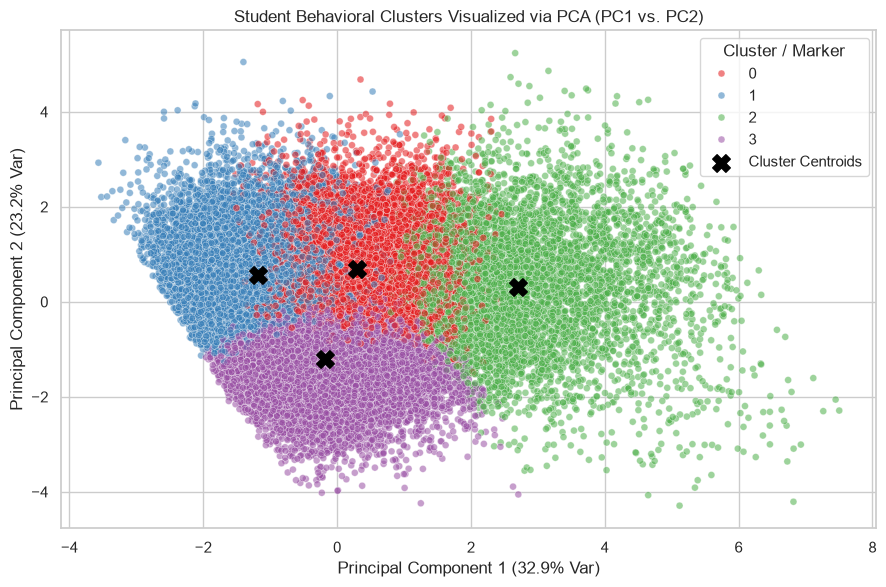


Clustering and PCA visualization complete.


In [46]:
# Fit K-Means Clustering (k=4) on standardized features
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df_clustered = X.copy()
df_clustered["Cluster"] = kmeans.fit_predict(X_scaled)

# Inspect cluster sizes and mean behavioral profiles in original units
cluster_counts = df_clustered["Cluster"].value_counts().sort_index()
cluster_profile = df_clustered.groupby("Cluster").mean()

print("--- Cluster Sizes ---")
print(cluster_counts)

print("\n--- Cluster Behavioral Profiles (Original Units) ---")
display(cluster_profile.round(2))
cluster_profile.to_csv("cluster_profiles_summary.csv")

# Project cluster centers onto PC1 and PC2 for visual reference
centroids_pca = pca.transform(kmeans.cluster_centers_)

# Visualize clusters in 2D PCA space (PC1 vs. PC2)
plt.figure(figsize=(9, 6))
sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=df_clustered["Cluster"],
    palette="Set1",
    s=25,
    alpha=0.55,
)
plt.scatter(
    centroids_pca[:, 0],
    centroids_pca[:, 1],
    c="black",
    marker="X",
    s=160,
    label="Cluster Centroids",
)
plt.title("Student Behavioral Clusters Visualized via PCA (PC1 vs. PC2)")
plt.xlabel(f"Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% Var)")
plt.ylabel(f"Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% Var)")
plt.legend(title="Cluster / Marker")
plt.tight_layout()
plt.savefig("pca_clusters_visualization.png", dpi=300)
plt.show()

print("\nClustering and PCA visualization complete.")

In [47]:
# Map cluster IDs to data-driven archetype names based on cluster_profile
cluster_names = {
    0: "Balanced & High-Retention (Higher Anxiety)",
    1: "Study-Anchored & Low-AI Users",
    2: "Heavy AI & High-Dependency Users",
    3: "Low-Study & Low-Momentum Users",
}
df_clustered["Cluster_Name"] = df_clustered["Cluster"].map(cluster_names)

# Print cluster counts and mean profiles by archetype name
archetype_summary = (
    df_clustered.groupby(["Cluster", "Cluster_Name"])[features]
    .mean()
    .round(2)
)
archetype_summary["Count"] = df_clustered.groupby(["Cluster", "Cluster_Name"]).size()

display(archetype_summary)

,,Weekly_GenAI_Hours,Traditional_Study_Hours,Perceived_AI_Dependency,Anxiety_Level_During_Exams,Skill_Retention_Score,GPA_Delta,Count
Cluster,Cluster_Name,,,,,,,
0,Balanced & High-Retention (Higher Anxiety),8.48,12.08,4.07,6.07,81.52,0.25,12682
1,Study-Anchored & Low-AI Users,5.05,15.39,2.62,2.96,79.69,0.32,15049
2,Heavy AI & High-Dependency Users,24.86,8.54,6.41,5.71,68.25,0.13,6307
3,Low-Study & Low-Momentum Users,5.08,7.64,2.74,3.50,70.56,0.08,15962


,k,SSE,Silhouette,Davies_Bouldin
0,2,237687.9643,0.2469,1.6851
1,3,202001.4647,0.1692,1.7377
2,4,185041.9257,0.1515,1.7558
3,5,172540.9578,0.1390,1.7475
4,6,162763.9595,0.1313,1.6628
5,7,154096.8220,0.1317,1.6599


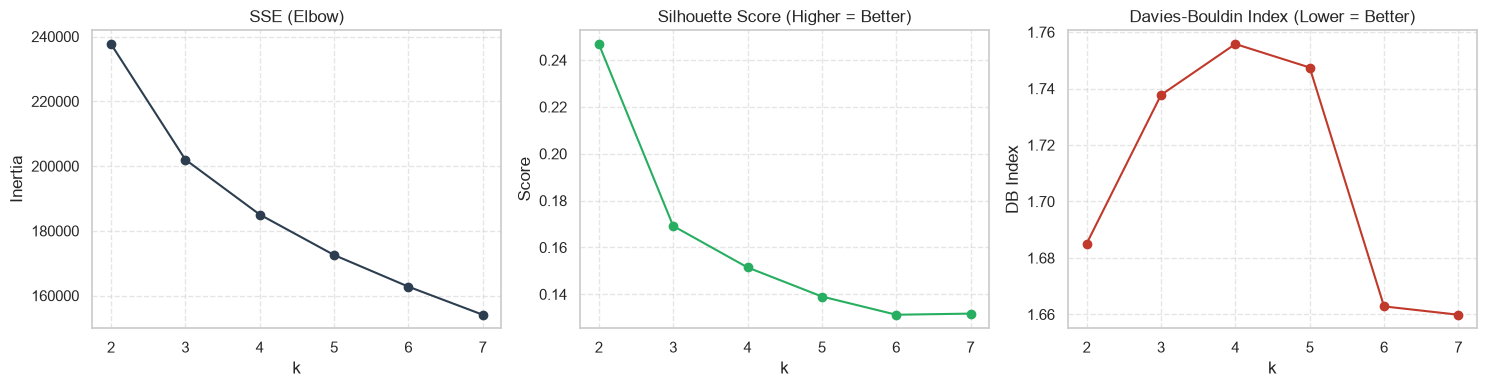

In [48]:
k_range = range(2, 8)
eval_rows = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    
    eval_rows.append({
        "k": k,
        "SSE": km.inertia_,
        "Silhouette": silhouette_score(X_scaled, labels),
        "Davies_Bouldin": davies_bouldin_score(X_scaled, labels)
    })

metrics_df = pd.DataFrame(eval_rows)
display(metrics_df.round(4))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(metrics_df["k"], metrics_df["SSE"], marker="o", color="#2c3e50")
axes[0].set_title("SSE (Elbow)")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inertia")
axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].plot(metrics_df["k"], metrics_df["Silhouette"], marker="o", color="#27ae60")
axes[1].set_title("Silhouette Score (Higher = Better)")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Score")
axes[1].grid(True, linestyle="--", alpha=0.5)

axes[2].plot(metrics_df["k"], metrics_df["Davies_Bouldin"], marker="o", color="#c0392b")
axes[2].set_title("Davies-Bouldin Index (Lower = Better)")
axes[2].set_xlabel("k")
axes[2].set_ylabel("DB Index")
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("cluster_validation_metrics.png", dpi=300, bbox_inches="tight")
plt.show()

##### Frequent Pattern Mining

In [52]:
# Create a clean working copy for association rule mining
assoc_cols = [
    "Weekly_GenAI_Hours",
    "Traditional_Study_Hours",
    "Perceived_AI_Dependency",
    "Anxiety_Level_During_Exams",
    "Skill_Retention_Score",
    "GPA_Delta",
]
df_assoc = df_fe[assoc_cols].dropna().copy()

# Discretize continuous variables into interpretable categories
df_assoc["GenAI_Usage"] = pd.cut(
    df_assoc["Weekly_GenAI_Hours"],
    bins=3,
    labels=["Low_AI", "Med_AI", "High_AI"],
)

df_assoc["Study_Time"] = pd.cut(
    df_assoc["Traditional_Study_Hours"],
    bins=3,
    labels=["Low_Study", "Med_Study", "High_Study"],
)

df_assoc["AI_Dependency"] = pd.cut(
    df_assoc["Perceived_AI_Dependency"],
    bins=3,
    labels=["Low_Dep", "Med_Dep", "High_Dep"],
)

df_assoc["Anxiety"] = pd.cut(
    df_assoc["Anxiety_Level_During_Exams"],
    bins=2,
    labels=["Low_Anxiety", "High_Anxiety"],
)

df_assoc["Retention"] = pd.cut(
    df_assoc["Skill_Retention_Score"],
    bins=2,
    labels=["Low_Retention", "High_Retention"],
)

df_assoc["GPA_Shift"] = pd.cut(
    df_assoc["GPA_Delta"],
    bins=[-float("inf"), 0.0, float("inf")],
    labels=["NonPositive_GPA_Delta", "Positive_GPA_Delta"],
)

# Convert categorical bins into boolean one-hot columns for Apriori
basket = pd.get_dummies(
    df_assoc[["GenAI_Usage", "Anxiety", "Retention", "GPA_Shift", "Study_Time", "AI_Dependency"]],
    dtype=bool,
)

# Mine frequent itemsets and rules with lift > 1.0 (positive association)
frequent_itemsets = apriori(basket, min_support=0.03, use_colnames=True)
rules = association_rules(
    frequent_itemsets,
    metric="lift",
    min_threshold=1.0,
)

print(f"Total Association Rules Found: {len(rules)}")

if len(rules) > 0:
    rules_display = rules.copy()
    rules_display["antecedents"] = rules_display["antecedents"].apply(
        lambda s: ", ".join(sorted(s))
    )
    rules_display["consequents"] = rules_display["consequents"].apply(
        lambda s: ", ".join(sorted(s))
    )

    top_rules = rules_display.sort_values(by="lift", ascending=False).head(10)
    print("\nTop Association Rules (Sorted by Lift):")
    display(
        top_rules[["antecedents", "consequents", "support", "confidence", "lift"]].round(3)
    )
else:
    print("\nNo rules above threshold. Frequent itemsets:")
    display(frequent_itemsets.sort_values(by="support", ascending=False))

Total Association Rules Found: 2128

Top Association Rules (Sorted by Lift):


,antecedents,consequents,support,confidence,lift
783,"AI_Dependency_Med_Dep, Anxiety_High_Anxiety, R...",GenAI_Usage_Med_AI,0.037,0.428,2.697
792,GenAI_Usage_Med_AI,"AI_Dependency_Med_Dep, Anxiety_High_Anxiety, R...",0.037,0.233,2.697
181,"AI_Dependency_Med_Dep, Anxiety_High_Anxiety",GenAI_Usage_Med_AI,0.040,0.425,2.675
184,GenAI_Usage_Med_AI,"AI_Dependency_Med_Dep, Anxiety_High_Anxiety",0.040,0.254,2.675
1691,"AI_Dependency_Med_Dep, Anxiety_High_Anxiety, R...","GPA_Shift_Positive_GPA_Delta, GenAI_Usage_Med_AI",0.031,0.358,2.663
1706,"GPA_Shift_Positive_GPA_Delta, GenAI_Usage_Med_AI","AI_Dependency_Med_Dep, Anxiety_High_Anxiety, R...",0.031,0.230,2.663
786,"AI_Dependency_Med_Dep, Anxiety_High_Anxiety","GenAI_Usage_Med_AI, Retention_High_Retention",0.037,0.390,2.654
789,"GenAI_Usage_Med_AI, Retention_High_Retention","AI_Dependency_Med_Dep, Anxiety_High_Anxiety",0.037,0.252,2.654
1707,"GenAI_Usage_Med_AI, Retention_High_Retention","AI_Dependency_Med_Dep, Anxiety_High_Anxiety, G...",0.031,0.211,2.644
1690,"AI_Dependency_Med_Dep, Anxiety_High_Anxiety, G...","GenAI_Usage_Med_AI, Retention_High_Retention",0.031,0.389,2.644


#### Nested Cross-Validation with Random Forest and Hyperparameter Tuning

   -> Fold 1 Accuracy: 45.72% | Best Hyperparameters: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 150}
   -> Fold 2 Accuracy: 45.31% | Best Hyperparameters: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 150}
   -> Fold 3 Accuracy: 44.74% | Best Hyperparameters: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}
   -> Fold 4 Accuracy: 44.71% | Best Hyperparameters: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 150}
   -> Fold 5 Accuracy: 44.72% | Best Hyperparameters: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 150}

Nested CV Average Accuracy: 45.04% (+/- 0.41%)


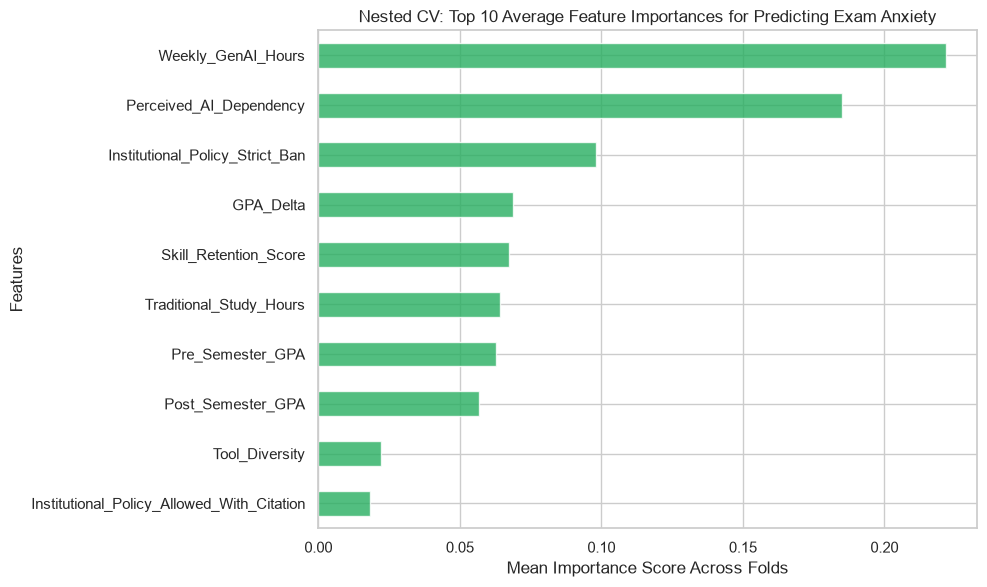


Nested cross-validation pipeline complete


In [55]:
# Define Target Variable: 3 Anxiety Classes (0 = Low, 1 = Medium, 2 = High)
df_fe["Target_Anxiety_Class"] = pd.qcut(
    df_fe["Anxiety_Level_During_Exams"],
    q=3,
    labels=[0, 1, 2],
)

# Drop leakage columns, identifiers, and target variables safely
drop_cols = [
    "Student_ID",
    "Anxiety_Level_During_Exams",
    "Target_Anxiety_Class",
    "Target_High_Anxiety",
]
X_raw = df_fe.drop(columns=drop_cols, errors="ignore")
y_class = df_fe["Target_Anxiety_Class"].astype(int)

# One-hot encode all categorical columns
X_encoded = pd.get_dummies(X_raw, drop_first=True)

# 4. Setup Nested Cross-Validation Structure
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# Hyperparameter grid for the inner loop optimization
param_grid = {
    "n_estimators": [100, 150],
    "max_depth": [10, 20, None],
    "min_samples_split": [2, 5],
}

outer_scores = []
feature_importances_list = []

for fold, (train_idx, test_idx) in enumerate(outer_cv.split(X_encoded, y_class)):
    X_train, X_test = X_encoded.iloc[train_idx], X_encoded.iloc[test_idx]
    y_train, y_test = y_class.iloc[train_idx], y_class.iloc[test_idx]

    # Inner loop: Grid Search for hyperparameter tuning
    rf = RandomForestClassifier(random_state=42)
    clf = GridSearchCV(
        estimator=rf,
        param_grid=param_grid,
        cv=inner_cv,
        scoring="accuracy",
        n_jobs=-1,
    )

    # Fit model (hyperparameter optimization happens entirely inside the inner folds)
    clf.fit(X_train, y_train)

    # Evaluate model on the unseen outer test fold
    y_pred = clf.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    outer_scores.append(acc)

    # Save the feature importances from this fold's best estimator
    feature_importances_list.append(clf.best_estimator_.feature_importances_)

    print(
        f"   -> Fold {fold + 1} Accuracy: {acc * 100:.2f}% | "
        f"Best Hyperparameters: {clf.best_params_}"
    )

# Summary Results
mean_acc = np.mean(outer_scores) * 100
std_acc = np.std(outer_scores) * 100
print(f"\nNested CV Average Accuracy: {mean_acc:.2f}% (+/- {std_acc:.2f}%)")

# Average Feature Importances across all outer folds
mean_importances = pd.Series(
    np.mean(feature_importances_list, axis=0), index=X_encoded.columns
)

plt.figure(figsize=(10, 6))
mean_importances.nlargest(10).sort_values().plot(kind="barh", color="#27ae60", alpha=0.8)
plt.title("Nested CV: Top 10 Average Feature Importances for Predicting Exam Anxiety")
plt.xlabel("Mean Importance Score Across Folds")
plt.ylabel("Features")
plt.tight_layout()
plt.savefig("random_forest_nested_cv_importance.png", dpi=300, bbox_inches="tight")
plt.show()

print("\nNested cross-validation pipeline complete")

   -> Fold 1 Accuracy: 46.04% | Best Hyperparameters: {'max_depth': 6, 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 250}
   -> Fold 2 Accuracy: 45.31% | Best Hyperparameters: {'max_depth': 8, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 250}
   -> Fold 3 Accuracy: 44.90% | Best Hyperparameters: {'max_depth': 6, 'min_samples_leaf': 3, 'min_samples_split': 2, 'n_estimators': 250}
   -> Fold 4 Accuracy: 44.49% | Best Hyperparameters: {'max_depth': 8, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 250}
   -> Fold 5 Accuracy: 44.61% | Best Hyperparameters: {'max_depth': 10, 'min_samples_leaf': 3, 'min_samples_split': 2, 'n_estimators': 250}

Nested CV Average Accuracy: 45.07% (+/- 0.56%)


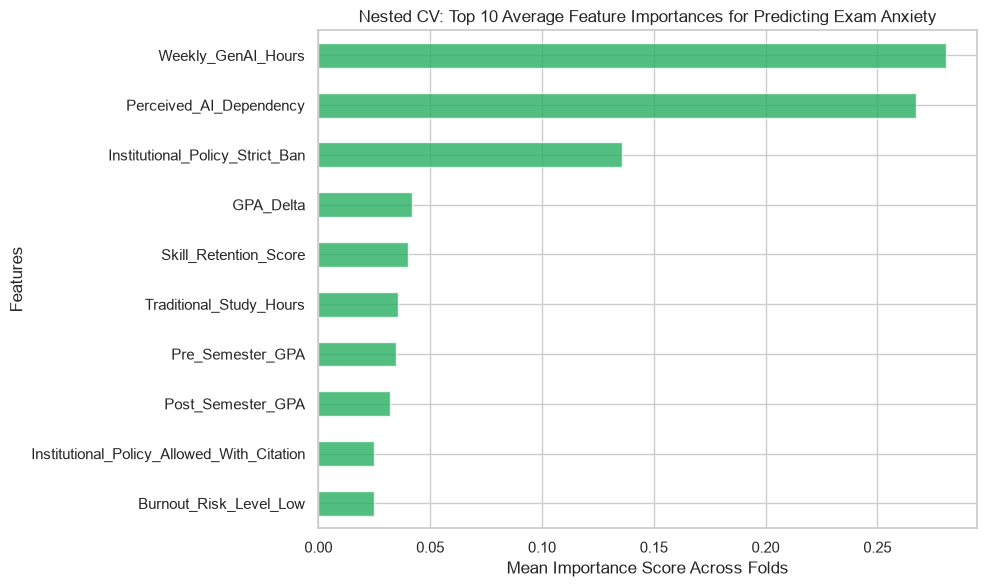


Nested cross-validation pipeline complete


In [58]:
# Define Target Variable: 3 Anxiety Classes (0 = Low, 1 = Medium, 2 = High)
df_fe["Target_Anxiety_Class"] = pd.qcut(
    df_fe["Anxiety_Level_During_Exams"],
    q=3,
    labels=[0, 1, 2],
)

# Drop leakage columns, identifiers, and target variables safely
drop_cols = [
    "Student_ID",
    "Anxiety_Level_During_Exams",
    "Target_Anxiety_Class",
    "Target_High_Anxiety",
]
X_raw = df_fe.drop(columns=drop_cols, errors="ignore")
y_class = df_fe["Target_Anxiety_Class"].astype(int)

# One-hot encode all categorical columns
X_encoded = pd.get_dummies(X_raw, drop_first=True)

# 5x3 Nested Cross-Validation Structure
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# Expanded hyperparameter grid with stronger regularization options
param_grid = {
    "n_estimators": [150, 250],
    "max_depth": [6, 8, 10, 15],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 3, 5],
}

outer_scores = []
best_params_per_fold = []
feature_importances_list = []

for fold, (train_idx, test_idx) in enumerate(outer_cv.split(X_encoded, y_class)):
    X_train, X_test = X_encoded.iloc[train_idx], X_encoded.iloc[test_idx]
    y_train, y_test = y_class.iloc[train_idx], y_class.iloc[test_idx]

    rf = RandomForestClassifier(random_state=42)
    clf = GridSearchCV(
        estimator=rf,
        param_grid=param_grid,
        cv=inner_cv,
        scoring="accuracy",
        n_jobs=-1,
    )

    clf.fit(X_train, y_train)

    y_pred = clf.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    outer_scores.append(acc)
    best_params_per_fold.append(clf.best_params_)
    feature_importances_list.append(clf.best_estimator_.feature_importances_)

    print(
        f"   -> Fold {fold + 1} Accuracy: {acc * 100:.2f}% | "
        f"Best Hyperparameters: {clf.best_params_}"
    )

mean_acc = np.mean(outer_scores) * 100
std_acc = np.std(outer_scores) * 100
print(f"\nNested CV Average Accuracy: {mean_acc:.2f}% (+/- {std_acc:.2f}%)")

# Average Feature Importances across all outer folds
mean_importances = pd.Series(
    np.mean(feature_importances_list, axis=0), index=X_encoded.columns
)

plt.figure(figsize=(10, 6))
mean_importances.nlargest(10).sort_values().plot(kind="barh", color="#27ae60", alpha=0.8)
plt.title("Nested CV: Top 10 Average Feature Importances for Predicting Exam Anxiety")
plt.xlabel("Mean Importance Score Across Folds")
plt.ylabel("Features")
plt.tight_layout()
plt.savefig("random_forest_nested_cv_importance.png", dpi=300, bbox_inches="tight")
plt.show()

print("\nNested cross-validation pipeline complete")

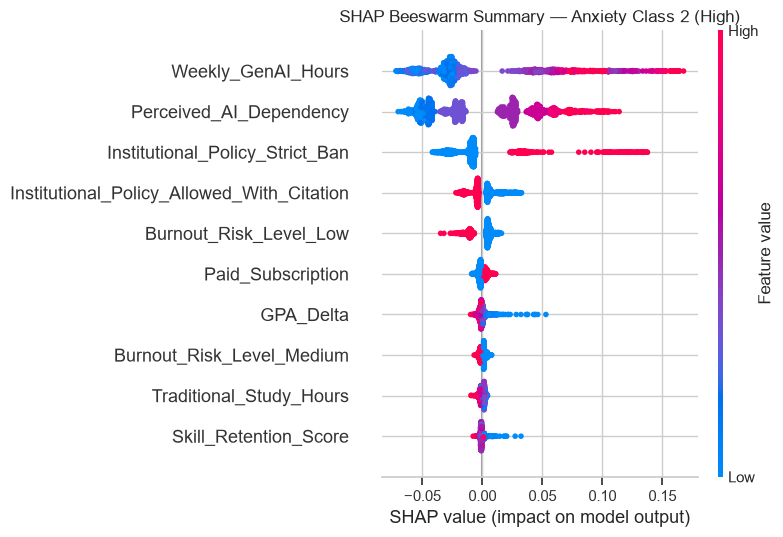

In [59]:
# Fit Random Forest using modal/consensus hyperparameters from nested CV
rf_shap = RandomForestClassifier(
    n_estimators=250,
    max_depth=6,
    min_samples_split=2,
    random_state=42,
    n_jobs=-1,
)
rf_shap.fit(X_train, y_train)

# Compute SHAP values on a sample for faster plotting
X_explain = X_test.iloc[:1500]
explainer = shap.TreeExplainer(rf_shap)
shap_values = explainer.shap_values(X_explain)

# Slice a single class (e.g., 2 = High Anxiety) for a standard beeswarm plot
target_class = 2
if isinstance(shap_values, list):
    shap_class = shap_values[target_class]
elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
    if shap_values.shape[-1] == len(rf_shap.classes_):
        shap_class = shap_values[:, :, target_class]
    else:
        shap_class = shap_values[:, target_class, :]
else:
    shap_class = shap_values

plt.figure(figsize=(10, 6))
shap.summary_plot(
    shap_class,
    X_explain,
    max_display=10,
    show=False,
)
plt.title(f"SHAP Beeswarm Summary — Anxiety Class {target_class} (High)")
plt.tight_layout()
plt.savefig("shap_beeswarm_high_anxiety.png", dpi=300, bbox_inches="tight")
plt.show()